# Árvore de Decisão e Gradient Boosting para Classificar Churn

Nesta atividade serão treinados e aplicados algoritmos supervisionados de aprendizado de máquina, Árvore de Decisão e Gradient Boosting. Esses algoritmos serão usados para conseguir identificar quais os clientes mais prováveis de dar churn (abandonar o plano) nos próximos 60 dias.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import (StratifiedKFold, GridSearchCV,
                                     cross_val_score, learning_curve)
from sklearn.metrics import (classification_report, roc_auc_score,
                              accuracy_score, average_precision_score,
                              confusion_matrix, RocCurveDisplay,
                              ConfusionMatrixDisplay, f1_score,
                              precision_score, recall_score)

# Carregar dados pré-processados
df_treino = pd.read_csv('./data/treino_tratado.csv')
df_teste  = pd.read_csv('./data/teste_tratado.csv')

# Separar features e target
X_train = df_treino.drop('churn', axis=1)
y_train = df_treino['churn']

X_test = df_teste.drop('churn', axis=1)
y_test = df_teste['churn']

feature_names = X_train.columns.tolist()

# Validação cruzada estratificada — usada em todos os módulos
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Treino : {X_train.shape}  |  Teste: {X_test.shape}")
print(f"Features ({len(feature_names)}): {feature_names}")

Treino : (3493, 13)  |  Teste: (1497, 13)
Features (13): ['tempo_ativo_dias', 'mensalidade_rs', 'qtd_chamados', 'atrasos_6m', 'fibra_optica', 'debito_automatico', 'atrasos_6m_faltante', 'tipo_contrato_Anual', 'tipo_contrato_Bienal', 'tipo_contrato_Mensal', 'forma_pagamento_Boleto', 'forma_pagamento_Cartão', 'forma_pagamento_Pix']


## Módulo 1: Setup e Baseline

Visão geral dos dados e treinamento de um modelo baseline (Decision Tree com parâmetros padrão) para estabelecer o piso de desempenho.

Treino — shape: (3493, 13)
Teste  — shape: (1497, 13)

Distribuição de churn no treino:
churn
Não-Churn (0)    2253
Churn (1)        1240
Taxa de churn: 35.5%


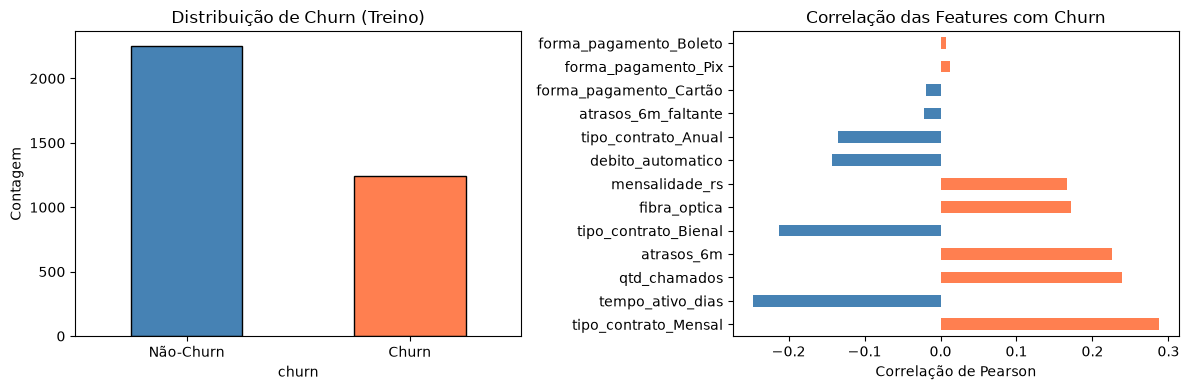

In [2]:
print(f"Treino — shape: {X_train.shape}")
print(f"Teste  — shape: {X_test.shape}")
print(f"\nDistribuição de churn no treino:")
print(y_train.value_counts().rename({0: 'Não-Churn (0)', 1: 'Churn (1)'}).to_string())
print(f"Taxa de churn: {y_train.mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y_train.value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color=['steelblue', 'coral'], edgecolor='k'
)
axes[0].set_title('Distribuição de Churn (Treino)')
axes[0].set_xticklabels(['Não-Churn', 'Churn'], rotation=0)
axes[0].set_ylabel('Contagem')

corr = df_treino.corr()['churn'].drop('churn').sort_values(key=abs, ascending=False)
corr.plot(kind='barh', ax=axes[1],
          color=['coral' if v > 0 else 'steelblue' for v in corr])
axes[1].set_title('Correlação das Features com Churn')
axes[1].set_xlabel('Correlação de Pearson')

plt.tight_layout()
plt.show()

In [3]:
baseline_dt = DecisionTreeClassifier(random_state=42)

baseline_scores = {
    'Recall':  cross_val_score(baseline_dt, X_train, y_train, cv=skf, scoring='recall'),
    'F1':      cross_val_score(baseline_dt, X_train, y_train, cv=skf, scoring='f1'),
    'ROC-AUC': cross_val_score(baseline_dt, X_train, y_train, cv=skf, scoring='roc_auc'),
}

print("=== BASELINE (Decision Tree — parâmetros padrão) ===")
for name, scores in baseline_scores.items():
    print(f"  {name:8s}: {scores.mean():.4f} ± {scores.std():.4f}")

=== BASELINE (Decision Tree — parâmetros padrão) ===
  Recall  : 0.4919 ± 0.0153
  F1      : 0.4923 ± 0.0149
  ROC-AUC : 0.6065 ± 0.0118


## Módulo 2: Árvore de Decisão — Controle de Complexidade e Interpretabilidade

Dois experimentos de poda são conduzidos para encontrar a árvore com melhor capacidade de generalização:
- **Experimento A (Pré-poda):** Busca de hiperparâmetros via `GridSearchCV`, focando em Recall.
- **Experimento B (Pós-poda):** Cost-complexity pruning — seleção do `ccp_alpha` ótimo por validação cruzada.

### Experimento A — Pré-poda (GridSearchCV)

Busca exaustiva de hiperparâmetros otimizando o Recall médio na validação cruzada. O teste **não é tocado**.

In [4]:
param_grid = {
    'max_depth':              [3, 5, 7, 10, None],
    'min_samples_split':      [2, 10, 20, 50],
    'min_samples_leaf':       [1, 5, 10, 20],
    'criterion':              ['gini', 'entropy'],
    'max_leaf_nodes':         [None, 20, 50],
    'min_impurity_decrease':  [0.0, 0.001, 0.01],
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=skf,
    scoring='recall',
    n_jobs=-1,
    verbose=0
)
grid_search.fit(X_train, y_train)

best_prepoda = grid_search.best_estimator_
best_prepoda_cv_recall = grid_search.best_score_

print("=== Melhor Árvore (Pré-poda) ===")
print(f"CV Recall:  {best_prepoda_cv_recall:.4f}")
print(f"Parâmetros: {grid_search.best_params_}")

=== Melhor Árvore (Pré-poda) ===
CV Recall:  0.5331
Parâmetros: {'criterion': 'gini', 'max_depth': 3, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.01, 'min_samples_leaf': 1, 'min_samples_split': 2}


### Experimento B — Pós-poda (Cost-Complexity Pruning)

Extrai o caminho de poda por complexidade de custo e seleciona o `ccp_alpha` que maximiza o Recall médio por validação cruzada.

=== Melhor Árvore (Pós-poda) ===
Melhor ccp_alpha: 0.000818
CV Recall:        0.5105


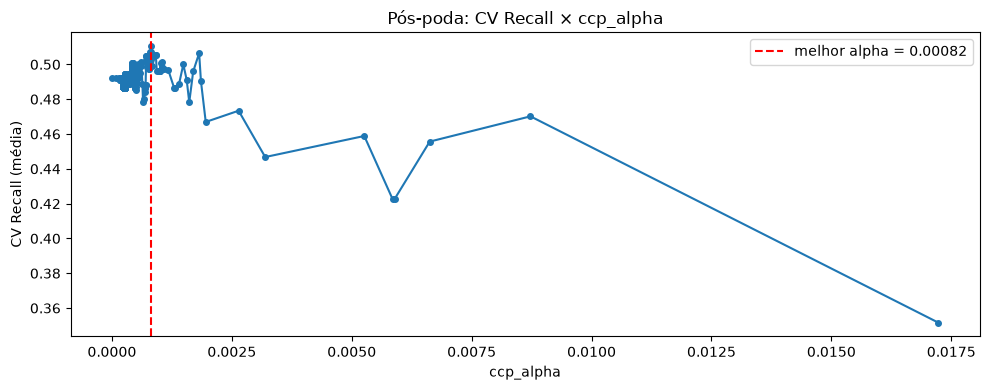

In [5]:
dt_full = DecisionTreeClassifier(random_state=42)
path = dt_full.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]  # remover último alpha (árvore trivial)

recall_por_alpha = []
for alpha in ccp_alphas:
    dt_alpha = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    scores = cross_val_score(dt_alpha, X_train, y_train, cv=skf, scoring='recall')
    recall_por_alpha.append(scores.mean())

best_alpha_idx = int(np.argmax(recall_por_alpha))
best_alpha = ccp_alphas[best_alpha_idx]
best_pospoda_cv_recall = recall_por_alpha[best_alpha_idx]

best_pospoda = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42)
best_pospoda.fit(X_train, y_train)

print("=== Melhor Árvore (Pós-poda) ===")
print(f"Melhor ccp_alpha: {best_alpha:.6f}")
print(f"CV Recall:        {best_pospoda_cv_recall:.4f}")

plt.figure(figsize=(10, 4))
plt.plot(ccp_alphas, recall_por_alpha, marker='o', linewidth=1.5, markersize=4)
plt.axvline(best_alpha, color='red', linestyle='--',
            label=f'melhor alpha = {best_alpha:.5f}')
plt.xlabel('ccp_alpha')
plt.ylabel('CV Recall (média)')
plt.title('Pós-poda: CV Recall × ccp_alpha')
plt.legend()
plt.tight_layout()
plt.show()

### Comparativo: Pré-poda vs. Pós-poda

Tabela com métricas de treino e validação cruzada para selecionar a árvore vencedora.

In [6]:
def avaliar_cv(modelo):
    r  = cross_val_score(modelo, X_train, y_train, cv=skf, scoring='recall').mean()
    f  = cross_val_score(modelo, X_train, y_train, cv=skf, scoring='f1').mean()
    au = cross_val_score(modelo, X_train, y_train, cv=skf, scoring='roc_auc').mean()
    modelo.fit(X_train, y_train)
    r_tr  = recall_score(y_train,  modelo.predict(X_train))
    f_tr  = f1_score(y_train,      modelo.predict(X_train))
    return {'Recall Treino': r_tr, 'Recall CV': r,
            'F1 Treino': f_tr,     'F1 CV': f, 'ROC-AUC CV': au}

resultados_ad = pd.DataFrame({
    'Pré-poda': avaliar_cv(best_prepoda),
    'Pós-poda': avaliar_cv(best_pospoda),
}).T

print("=== Comparativo Pré-poda vs. Pós-poda ===")
print(resultados_ad.to_string(float_format='{:.4f}'.format))

if best_prepoda_cv_recall >= best_pospoda_cv_recall:
    best_tree = best_prepoda
    print(f"\nÁrvore vencedora: Pré-poda  (CV Recall = {best_prepoda_cv_recall:.4f})")
else:
    best_tree = best_pospoda
    print(f"\nÁrvore vencedora: Pós-poda  (CV Recall = {best_pospoda_cv_recall:.4f})")

best_tree.fit(X_train, y_train)

=== Comparativo Pré-poda vs. Pós-poda ===
          Recall Treino  Recall CV  F1 Treino  F1 CV  ROC-AUC CV
Pré-poda         0.5855     0.5331     0.5760 0.5479      0.6856
Pós-poda         0.5411     0.5105     0.6184 0.5496      0.7276

Árvore vencedora: Pré-poda  (CV Recall = 0.5331)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.01
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_n

### Extração de Regras da Árvore Vencedora

Mapeamento das regras condicionais (SE → ENTÃO) de maior risco de churn nos primeiros 3 níveis da árvore.

=== Regras Condicionais da Árvore Vencedora (profundidade ≤ 3) ===
|--- tipo_contrato_Mensal <= 0.50
|   |--- class: 0
|--- tipo_contrato_Mensal >  0.50
|   |--- tempo_ativo_dias <= 868.00
|   |   |--- class: 1
|   |--- tempo_ativo_dias >  868.00
|   |   |--- class: 0



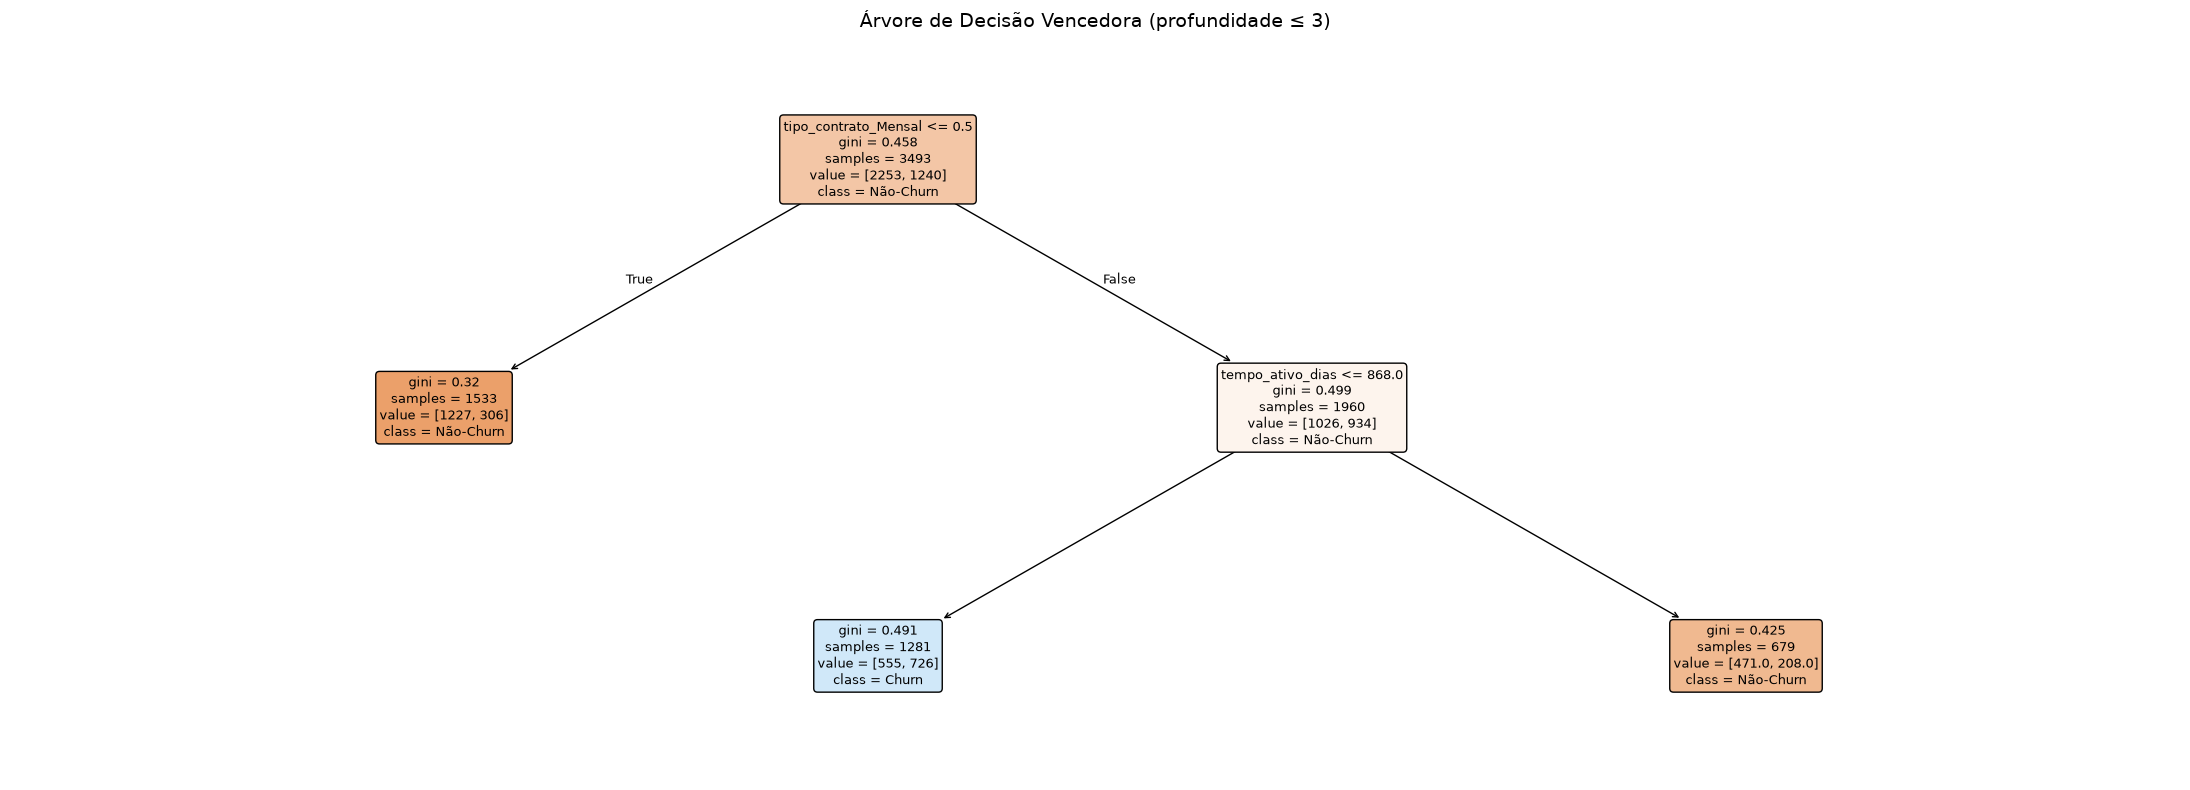

In [7]:
print("=== Regras Condicionais da Árvore Vencedora (profundidade ≤ 3) ===")
print(export_text(best_tree, feature_names=feature_names, max_depth=3))

fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(
    best_tree,
    max_depth=3,
    feature_names=feature_names,
    class_names=['Não-Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
ax.set_title('Árvore de Decisão Vencedora (profundidade ≤ 3)', fontsize=14)
plt.tight_layout()
plt.show()

## Módulo 3: Gradient Boosting com XGBoost — Otimização Bayesiana (Optuna)

Otimização de hiperparâmetros via Optuna com `MedianPruner` para eliminar trials não promissores. Objetivo: maximizar o Recall médio na validação cruzada. O conjunto de teste **não é utilizado** nesta etapa.

In [8]:
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

def objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth':        trial.suggest_int('max_depth', 3, 9),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma':            trial.suggest_float('gamma', 0, 5),
        'reg_alpha':        trial.suggest_float('reg_alpha', 0, 10),
        'reg_lambda':       trial.suggest_float('reg_lambda', 1, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, neg_pos_ratio * 2),
        'random_state':     42,
        'verbosity':        0,
        'eval_metric':      'logloss',
    }
    model = XGBClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='recall')
    return scores.mean()

study = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=5)
)
study.optimize(objective, n_trials=50, timeout=180, show_progress_bar=False)

print("=== Melhor XGBoost (Optuna) ===")
print(f"Melhor CV Recall: {study.best_value:.4f}")
print(f"Melhores parâmetros:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

best_xgb_params = {**study.best_params,
                   'random_state': 42, 'verbosity': 0, 'eval_metric': 'logloss'}
best_xgb = XGBClassifier(**best_xgb_params)
best_xgb.fit(X_train, y_train)

=== Melhor XGBoost (Optuna) ===
Melhor CV Recall: 0.7016
Melhores parâmetros:
  n_estimators: 437
  learning_rate: 0.2536999076681772
  max_depth: 8
  subsample: 0.8394633936788146
  colsample_bytree: 0.5780093202212182
  gamma: 0.7799726016810132
  reg_alpha: 0.5808361216819946
  reg_lambda: 8.795585311974417
  scale_pos_weight: 2.58325937770429


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5780093202212182
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


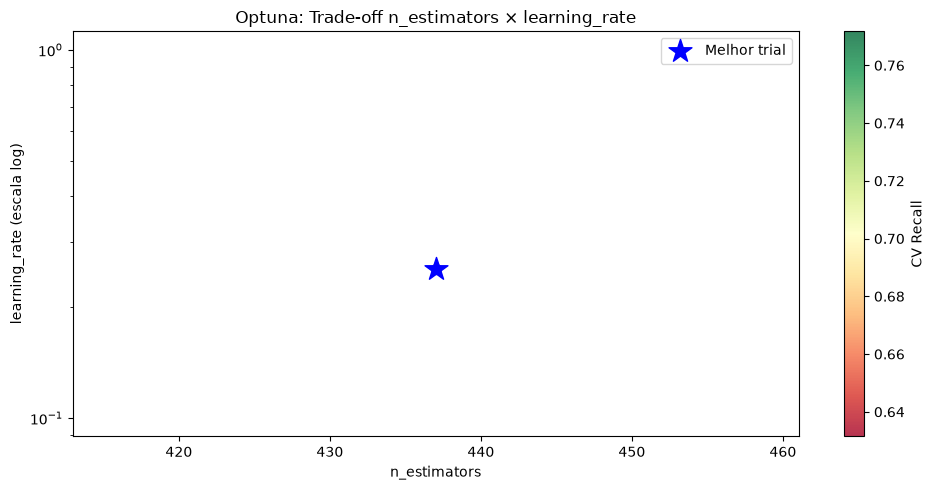

In [9]:
trials_df = study.trials_dataframe()
trials_df = trials_df.dropna(subset=['value']).copy()

plt.figure(figsize=(10, 5))
sc = plt.scatter(
    trials_df['params_n_estimators'],
    trials_df['params_learning_rate'],
    c=trials_df['value'],
    cmap='RdYlGn',
    alpha=0.8,
    edgecolors='k',
    linewidths=0.4,
    s=60
)
plt.colorbar(sc, label='CV Recall')
best_trial = study.best_trial
plt.scatter(
    best_trial.params['n_estimators'],
    best_trial.params['learning_rate'],
    marker='*', s=300, color='blue', zorder=5, label='Melhor trial'
)
plt.xlabel('n_estimators')
plt.ylabel('learning_rate (escala log)')
plt.yscale('log')
plt.title('Optuna: Trade-off n_estimators × learning_rate')
plt.legend()
plt.tight_layout()
plt.show()

## Módulo 4: Avaliação Final, Diagnóstico de Overfitting e Explicabilidade

Os dois modelos vencedores são avaliados no conjunto de teste **pela primeira vez** nesta etapa. Nenhuma informação do teste foi utilizada nos módulos anteriores (zero data leakage).

In [10]:
def metricas_completas(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    return {
        'Recall':    recall_score(y, y_pred),
        'Precision': precision_score(y, y_pred),
        'F1':        f1_score(y, y_pred),
        'ROC-AUC':   roc_auc_score(y, y_prob),
        'PR-AUC':    average_precision_score(y, y_prob),
        'Accuracy':  accuracy_score(y, y_pred),
    }

print("=== Avaliação Final no Conjunto de Teste ===\n")
metricas_dt_test  = metricas_completas(best_tree, X_test, y_test)
metricas_xgb_test = metricas_completas(best_xgb,  X_test, y_test)

eval_df = pd.DataFrame({
    'Árvore de Decisão': metricas_dt_test,
    'XGBoost':           metricas_xgb_test,
})
print(eval_df.to_string(float_format='{:.4f}'.format))

print("\n=== Classification Report — Árvore de Decisão ===")
print(classification_report(y_test, best_tree.predict(X_test),
                             target_names=['Não-Churn', 'Churn']))

print("=== Classification Report — XGBoost ===")
print(classification_report(y_test, best_xgb.predict(X_test),
                             target_names=['Não-Churn', 'Churn']))

=== Avaliação Final no Conjunto de Teste ===

           Árvore de Decisão  XGBoost
Recall                0.5489   0.6823
Precision             0.5387   0.5483
F1                    0.5438   0.6080
ROC-AUC               0.6571   0.7586
PR-AUC                0.4719   0.6172
Accuracy              0.6727   0.6874

=== Classification Report — Árvore de Decisão ===
              precision    recall  f1-score   support

   Não-Churn       0.75      0.74      0.74       965
       Churn       0.54      0.55      0.54       532

    accuracy                           0.67      1497
   macro avg       0.64      0.64      0.64      1497
weighted avg       0.67      0.67      0.67      1497

=== Classification Report — XGBoost ===
              precision    recall  f1-score   support

   Não-Churn       0.80      0.69      0.74       965
       Churn       0.55      0.68      0.61       532

    accuracy                           0.69      1497
   macro avg       0.67      0.69      0.67      149

=== Gap Treino × Teste (diagnóstico de overfitting) ===
           DT Treino  DT Teste  DT Gap  XGB Treino  XGB Teste  XGB Gap
Recall        0.5855    0.5489  0.0366      0.9637     0.6823   0.2814
Precision     0.5667    0.5387  0.0280      0.7278     0.5483   0.1794
F1            0.5760    0.5438  0.0322      0.8293     0.6080   0.2212
ROC-AUC       0.6895    0.6571  0.0323      0.9583     0.7586   0.1997
PR-AUC        0.4994    0.4719  0.0275      0.9168     0.6172   0.2997
Accuracy      0.6940    0.6727  0.0213      0.8591     0.6874   0.1718


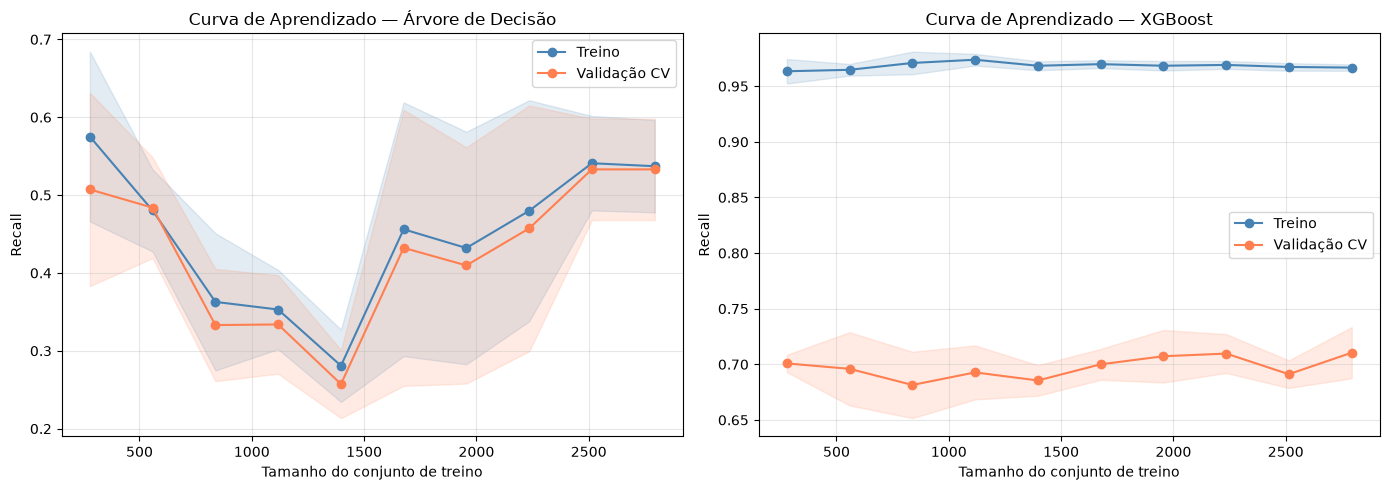

In [11]:
# --- Gap treino × teste ---
metricas_dt_train  = metricas_completas(best_tree, X_train, y_train)
metricas_xgb_train = metricas_completas(best_xgb,  X_train, y_train)

gap_data = {}
for metrica in metricas_dt_test:
    gap_data[metrica] = {
        'DT Treino':  metricas_dt_train[metrica],
        'DT Teste':   metricas_dt_test[metrica],
        'DT Gap':     abs(metricas_dt_train[metrica] - metricas_dt_test[metrica]),
        'XGB Treino': metricas_xgb_train[metrica],
        'XGB Teste':  metricas_xgb_test[metrica],
        'XGB Gap':    abs(metricas_xgb_train[metrica] - metricas_xgb_test[metrica]),
    }

gap_df = pd.DataFrame(gap_data).T
print("=== Gap Treino × Teste (diagnóstico de overfitting) ===")
print(gap_df.to_string(float_format='{:.4f}'.format))

# --- Curvas de Aprendizado ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in zip(axes,
                             [best_tree, best_xgb],
                             ['Árvore de Decisão', 'XGBoost']):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=skf, scoring='recall',
        train_sizes=np.linspace(0.1, 1.0, 10),
        n_jobs=-1
    )
    ax.plot(train_sizes, train_scores.mean(axis=1), 'o-',
            label='Treino', color='steelblue')
    ax.fill_between(train_sizes,
                    train_scores.mean(axis=1) - train_scores.std(axis=1),
                    train_scores.mean(axis=1) + train_scores.std(axis=1),
                    alpha=0.15, color='steelblue')
    ax.plot(train_sizes, val_scores.mean(axis=1), 'o-',
            label='Validação CV', color='coral')
    ax.fill_between(train_sizes,
                    val_scores.mean(axis=1) - val_scores.std(axis=1),
                    val_scores.mean(axis=1) + val_scores.std(axis=1),
                    alpha=0.15, color='coral')
    ax.set_title(f'Curva de Aprendizado — {title}')
    ax.set_xlabel('Tamanho do conjunto de treino')
    ax.set_ylabel('Recall')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

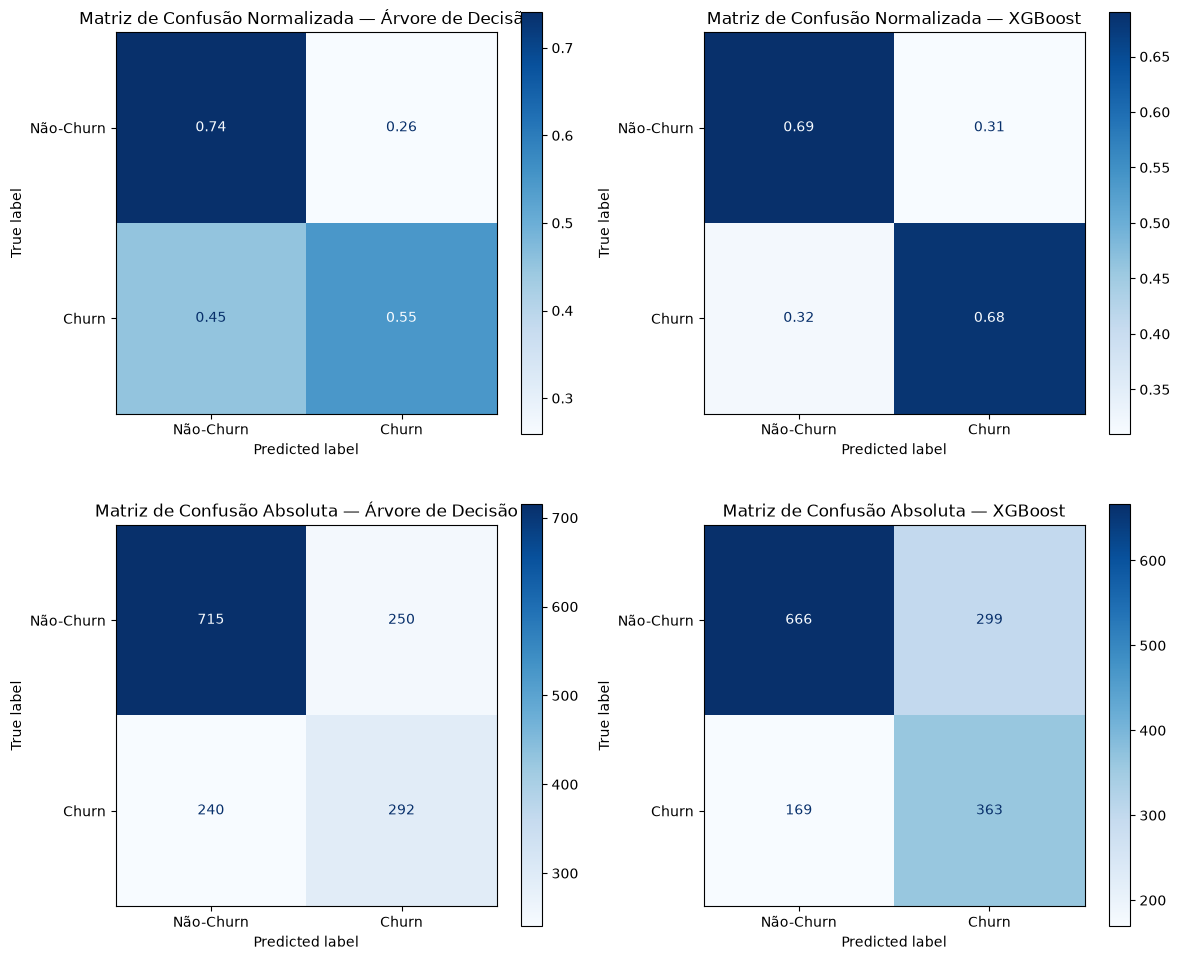

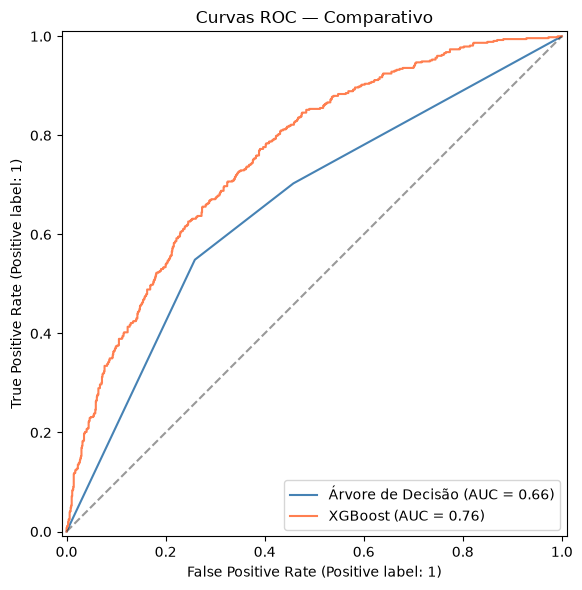

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for col, (model, name) in enumerate([(best_tree, 'Árvore de Decisão'),
                                      (best_xgb,  'XGBoost')]):
    y_pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['Não-Churn', 'Churn'],
        normalize='true', cmap='Blues', ax=axes[0, col]
    )
    axes[0, col].set_title(f'Matriz de Confusão Normalizada — {name}')

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['Não-Churn', 'Churn'],
        normalize=None, cmap='Blues', ax=axes[1, col]
    )
    axes[1, col].set_title(f'Matriz de Confusão Absoluta — {name}')

plt.tight_layout()
plt.show()

# Curvas ROC lado a lado
fig, ax = plt.subplots(figsize=(8, 6))
for model, name, color in [(best_tree, 'Árvore de Decisão', 'steelblue'),
                            (best_xgb,  'XGBoost',           'coral')]:
    RocCurveDisplay.from_estimator(model, X_test, y_test,
                                   name=name, curve_kwargs={'color': color}, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax.set_title('Curvas ROC — Comparativo')
plt.tight_layout()
plt.show()

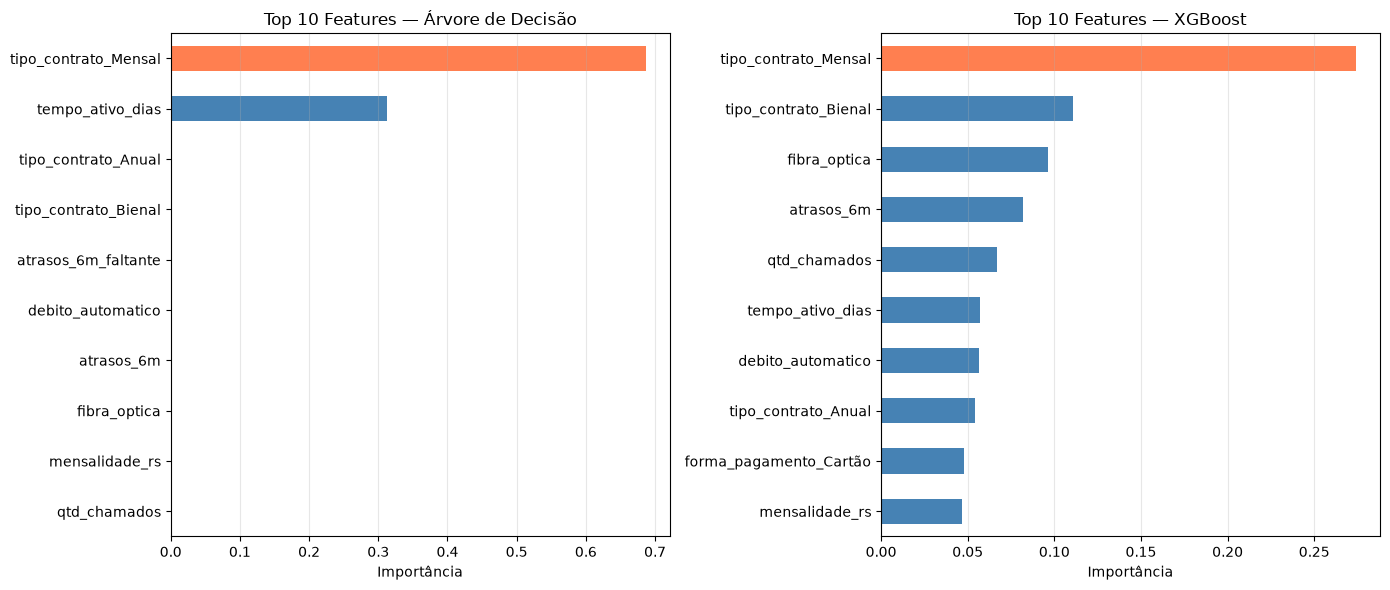

=== Importância das Features (ordenada por XGBoost) ===
                        Árvore de Decisão  XGBoost
tipo_contrato_Mensal               0.6867   0.2742
tipo_contrato_Bienal               0.0000   0.1105
fibra_optica                       0.0000   0.0965
atrasos_6m                         0.0000   0.0816
qtd_chamados                       0.0000   0.0667
tempo_ativo_dias                   0.3133   0.0571
debito_automatico                  0.0000   0.0567
tipo_contrato_Anual                0.0000   0.0544
forma_pagamento_Cartão             0.0000   0.0480
mensalidade_rs                     0.0000   0.0465
forma_pagamento_Boleto             0.0000   0.0382
forma_pagamento_Pix                0.0000   0.0376
atrasos_6m_faltante                0.0000   0.0319


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, model, name in [(axes[0], best_tree, 'Árvore de Decisão'),
                        (axes[1], best_xgb,  'XGBoost')]:
    importances = pd.Series(model.feature_importances_, index=feature_names)
    top10 = importances.nlargest(10).sort_values()
    colors = ['coral' if v == top10.max() else 'steelblue' for v in top10]
    top10.plot(kind='barh', ax=ax, color=colors)
    ax.set_title(f'Top 10 Features — {name}')
    ax.set_xlabel('Importância')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

imp_df = pd.DataFrame({
    'Árvore de Decisão': pd.Series(best_tree.feature_importances_, index=feature_names),
    'XGBoost':           pd.Series(best_xgb.feature_importances_,  index=feature_names),
}).sort_values('XGBoost', ascending=False)

print("=== Importância das Features (ordenada por XGBoost) ===")
print(imp_df.to_string(float_format='{:.4f}'.format))

In [15]:
# Recomputar métricas de treino para todos os modelos
baseline_dt_full = DecisionTreeClassifier(random_state=42)
baseline_dt_full.fit(X_train, y_train)

rows = {}

for modelo, nome in [
    (baseline_dt_full, 'Baseline (DT padrão)'),
    (best_prepoda,     'AD Pré-poda'),
    (best_pospoda,     'AD Pós-poda'),
    (best_xgb,         'XGBoost Optuna'),
]:
    m  = metricas_completas(modelo, X_train, y_train)
    mt = metricas_completas(modelo, X_test,  y_test)
    rows[nome] = {
        'Recall Treino':   m['Recall'],
        'Recall Teste':    mt['Recall'],
        'F1 Treino':       m['F1'],
        'F1 Teste':        mt['F1'],
        'ROC-AUC Treino':  m['ROC-AUC'],
        'ROC-AUC Teste':   mt['ROC-AUC'],
        'PR-AUC Teste':    mt['PR-AUC'],
    }

resumo = pd.DataFrame(rows).T

print("=" * 75)
print("RESUMO EXECUTIVO — COMPARATIVO COMPLETO DE MODELOS")
print("=" * 75)
print(resumo.to_string(float_format='{:.4f}'.format))

melhor = resumo['Recall Teste'].idxmax()
print(f"\nMelhor modelo por Recall no Teste: {melhor} "
      f"({resumo.loc[melhor, 'Recall Teste']:.4f})")

RESUMO EXECUTIVO — COMPARATIVO COMPLETO DE MODELOS
                      Recall Treino  Recall Teste  F1 Treino  F1 Teste  ROC-AUC Treino  ROC-AUC Teste  PR-AUC Teste
Baseline (DT padrão)         0.9992        0.5301     0.9996    0.5331          1.0000         0.6386        0.4512
AD Pré-poda                  0.5855        0.5489     0.5760    0.5438          0.6895         0.6571        0.4719
AD Pós-poda                  0.5411        0.4492     0.6184    0.5270          0.8146         0.7547        0.6159
XGBoost Optuna               0.9637        0.6823     0.8293    0.6080          0.9583         0.7586        0.6172

Melhor modelo por Recall no Teste: XGBoost Optuna (0.6823)
